In [6]:
import pandas as pd
import re
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import matplotlib as mpl


from scipy.spatial.transform import rotation
from sklearn.externals.array_api_compat import size

from sklearn.cluster import DBSCAN
from sklearn import metrics
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score

In [7]:
main_data = pd.read_csv('data/Medicare_Physician_Other_Practitioners_by_Provider_and_Service_2024.csv')
states = [
    "MD", "IL", "OH", "CO", "PA", "OK", "CA", "FL", "TX", "KY", "SC", "NV", "MO", "NY", "NJ", "VA", "LA", "TN", "MA", "OR","MI", "WA", "ME", "MN", "CT", "GA", "NC", "MS", "IA", "ND","ID", "NE", "AZ", "AL", "PR", "HI", "RI", "DC", "IN", "NM","AR", "WV", "VT", "NH", "AE", "KS", "DE", "WI", "MT", "WY","SD", "UT", "AK", "GU", "ZZ", "VI", "MP", "AP", "XX", "AA","FM", "AS"
]
main_data

C:\Users\tjwat\AppData\Local\Temp\ipykernel_26076\49599299.py:1: DtypeWarning: Columns (10: Rndrng_Prvdr_State_FIPS, 11: Rndrng_Prvdr_Zip5) have mixed types. Specify dtype option on import or set low_memory=False.
  main_data = pd.read_csv('data/Medicare_Physician_Other_Practitioners_by_Provider_and_Service_2024.csv')


,Rndrng_NPI,Rndrng_Prvdr_Last_Org_Name,Rndrng_Prvdr_First_Name,Rndrng_Prvdr_MI,Rndrng_Prvdr_Crdntls,Rndrng_Prvdr_Ent_Cd,Rndrng_Prvdr_St1,Rndrng_Prvdr_St2,Rndrng_Prvdr_City,Rndrng_Prvdr_State_Abrvtn,...,HCPCS_Desc,HCPCS_Drug_Ind,Place_Of_Srvc,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
0,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Initial hospital care with straightforward or ...,N,F,36,36.0,36,284.378889,79.063889,60.828889,62.376389
1,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Initial hospital care with straightforward or ...,N,F,150,150.0,150,352.176333,126.340800,95.675600,96.007133
2,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Initial hospital care with moderate level of m...,N,F,63,63.0,63,783.997302,170.360000,134.300476,131.999365
3,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Subsequent hospital care with straightforward ...,N,F,11,16.0,16,122.125000,47.832500,33.350625,33.706250
4,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Subsequent hospital care with moderate levelof...,N,F,37,70.0,70,583.606857,81.428571,62.728714,58.486857
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9781668,1992999825,Deschenes,Geoffrey,R,M.D.,I,1100 9th Ave,Ms:m4-Pfs,Seattle,WA,...,Established patient office or other outpatient...,N,O,80,92.0,92,330.000000,140.840326,104.658370,93.407065
9781669,1992999874,Joffe,Gabriella,NaN,NaN,I,5620 Brook Rd,NaN,Richmond,VA,...,Initial hospital care with moderate level of m...,N,F,36,36.0,36,780.583333,165.405000,131.781389,133.834444
9781670,1992999874,Joffe,Gabriella,NaN,NaN,I,5620 Brook Rd,NaN,Richmond,VA,...,Subsequent hospital care with moderate levelof...,N,F,188,329.0,329,278.127660,74.811337,59.662888,61.002462
9781671,1992999874,Joffe,Gabriella,NaN,NaN,I,5620 Brook Rd,NaN,Richmond,VA,...,Subsequent hospital care with moderate levelof...,N,F,99,153.0,153,398.522876,113.171438,89.568366,90.994967


Text(0, 0.5, 'Amount of Providers')

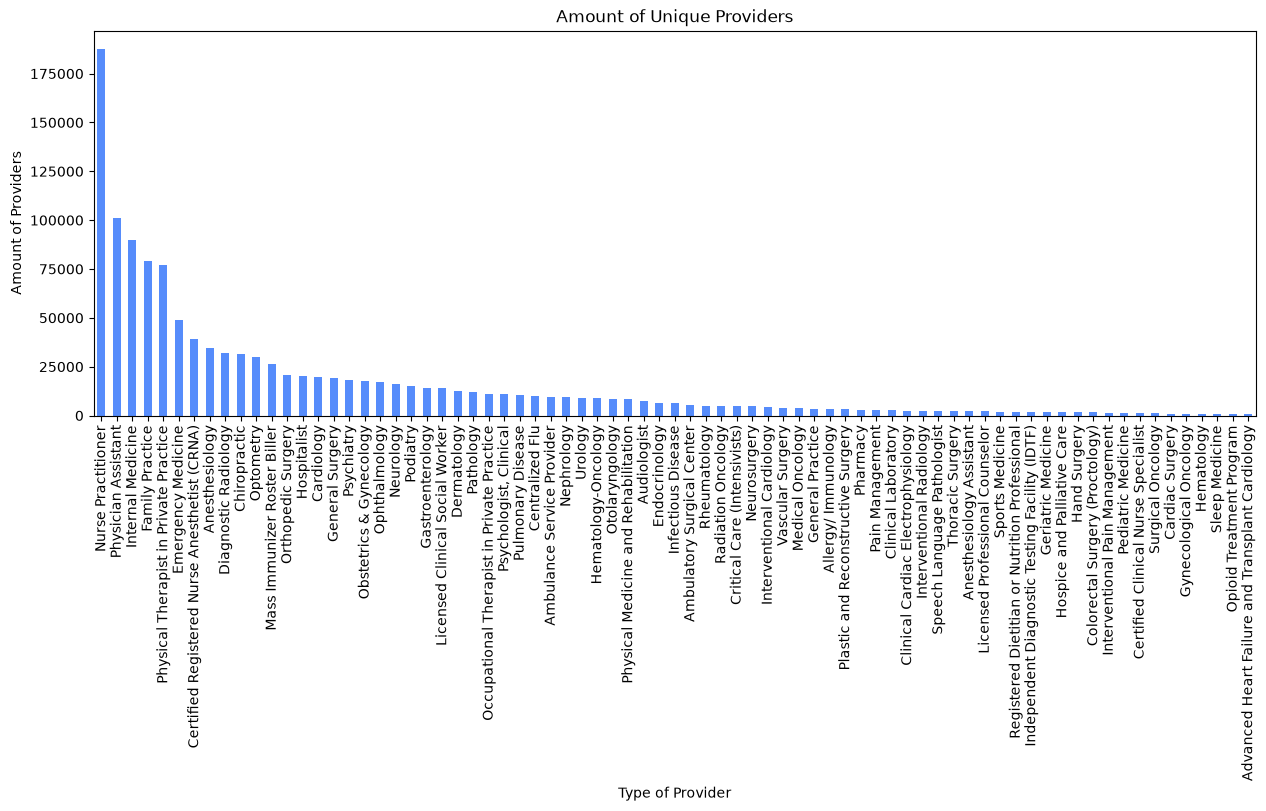

In [8]:
data_NPI = main_data.groupby('Rndrng_Prvdr_Type')['Rndrng_NPI'].nunique().sort_values(ascending=False).head(75)
fig, ax = plt.subplots(figsize=(15,5))
data_NPI.plot(kind='bar')
plt.title('Amount of Unique Providers')
plt.xlabel('Type of Provider')
plt.ylabel('Amount of Providers')

In [15]:


for state in states:
    state_data = main_data[main_data['Rndrng_Prvdr_State_Abrvtn']==state]
    data_NPI = state_data.groupby('Rndrng_Prvdr_Type')['Rndrng_NPI'].nunique().sort_values(ascending=False).head(75)
    fig, ax = plt.subplots(figsize=(15,5))
    data_NPI.plot(kind='bar')
    plt.title(f'Amount of Unique Providers in {state}')
    plt.xlabel('Type of Provider')
    plt.ylabel('Amount of Providers')
    plt.savefig(f"Amount_of_Unique_providers_in_{state}_light.png", dpi=300, bbox_inches='tight')
    plt.close()

In [16]:
for type in data_types_arr:
        provider_type = type
        type_data = main_data[main_data['Rndrng_Prvdr_Type']==f"{provider_type}"]
        type_data_avgPrice = type_data.groupby('Rndrng_Prvdr_Last_Org_Name')['Avg_Sbmtd_Chrg'].mean().sort_values(ascending=False).head(100)
        fig, ax = plt.subplots(figsize=(15,5))
        type_data_avgPrice.plot(kind='bar', ax = ax)
        plt.title(f'Average Charge of {provider_type} (top 100)')
        plt.xlabel('Provider Name')
        plt.ylabel('Amount in $')
        if "/" in type:
            type_new = type.replace("/"," or ")
            provider_type = re.sub(r" +", " ", type_new).strip()
        plt.savefig(f"Average_Charge_of_{provider_type}_light.png", dpi=300, bbox_inches='tight')
        plt.close()


KeyboardInterrupt


KeyboardInterrupt



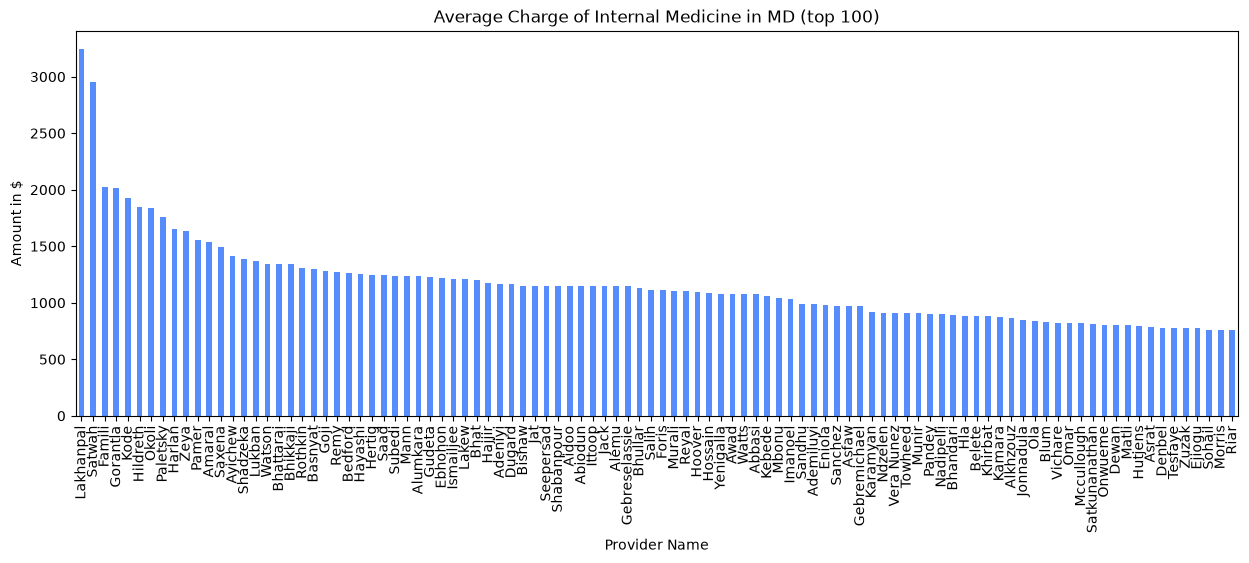

In [17]:
for state in states:
    state_data = main_data[main_data['Rndrng_Prvdr_State_Abrvtn']==state]
    for type in data_types_arr:
        provider_type = type
        type_data = state_data[state_data['Rndrng_Prvdr_Type']==f"{provider_type}"]
        if type_data.empty:
            continue
        type_data_avgPrice = type_data.groupby('Rndrng_Prvdr_Last_Org_Name')['Avg_Sbmtd_Chrg'].mean().sort_values(ascending=False).head(100)
        fig, ax = plt.subplots(figsize=(15,5))
        type_data_avgPrice.plot(kind='bar', ax=ax)
        plt.title(f'Average Charge of {provider_type} in {state} (top 100)')
        plt.xlabel('Provider Name')
        plt.ylabel('Amount in $')
        if "/" in type:
            type_new = type.replace("/"," or ")
            provider_type = re.sub(r" +", " ", type_new).strip()
        plt.savefig(f"Average_Charge_of_{provider_type}_in_{state}_light.png", dpi=300, bbox_inches='tight')
        plt.close()




In [9]:
data_types = main_data.value_counts('Rndrng_Prvdr_Type')
data_types_arr = data_types.index.tolist()
for type in data_types_arr:
    if "/" in type:
        type_new = type.replace("/"," or ")
        type_clean = re.sub(r" +", " ", type_new).strip()
        print(type_clean)

Allergy or Immunology
Unknown Supplier or Provider Specialty


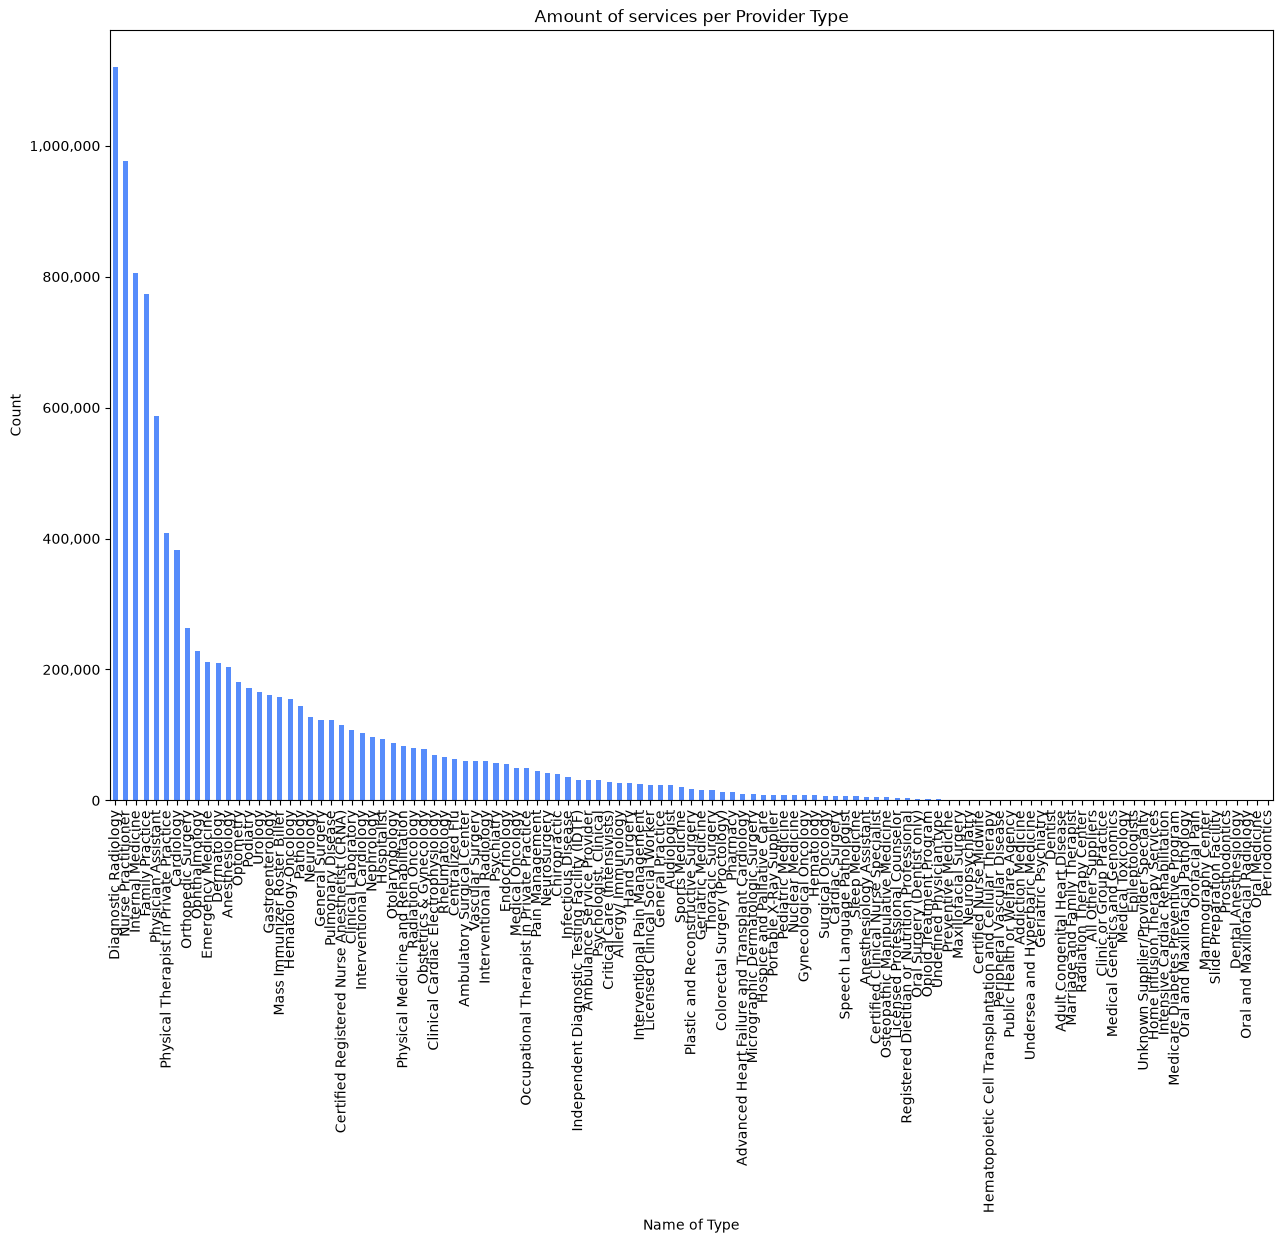

In [10]:
main_type_counts = main_data['Rndrng_Prvdr_Type'].value_counts()
fig, ax = plt.subplots(figsize=(15,10))
main_type_counts.plot(kind='bar')
ax.set_xticklabels(main_type_counts.index, fontsize=10)
ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
plt.xlabel('Name of Type')
plt.ylabel('Count')
plt.title('Amount of services per Provider Type')
plt.show()

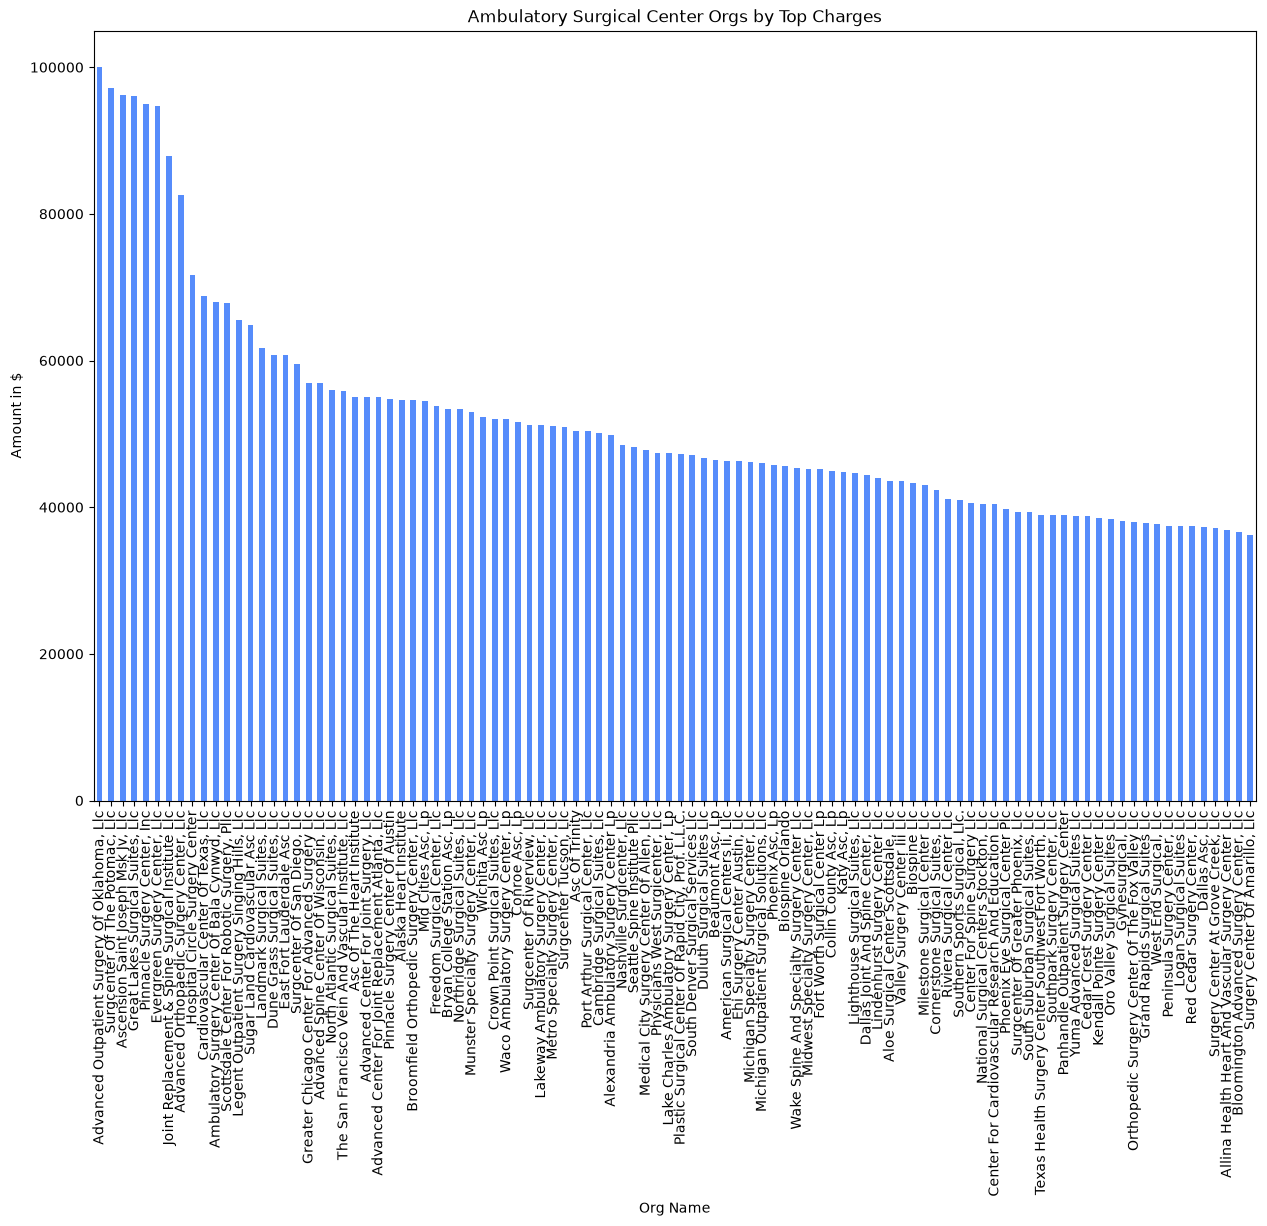

In [11]:
ambulatory = main_data[main_data['Rndrng_Prvdr_Type']=='Ambulatory Surgical Center']
ambulatory_Org_avgCharge = ambulatory.groupby('Rndrng_Prvdr_Last_Org_Name')['Avg_Sbmtd_Chrg'].mean().sort_values(ascending=False).head(100)
fig, ax = plt.subplots(figsize=(15,10))
ambulatory_Org_avgCharge.plot(kind='bar')
ax.set_xticks(range(len(ambulatory_Org_avgCharge.index)))
ax.set_xticklabels(ambulatory_Org_avgCharge.index, rotation=90, fontsize=10)
plt.xlabel('Org Name')
plt.ylabel('Amount in $')
plt.title('Ambulatory Surgical Center Orgs by Top Charges')
plt.show()

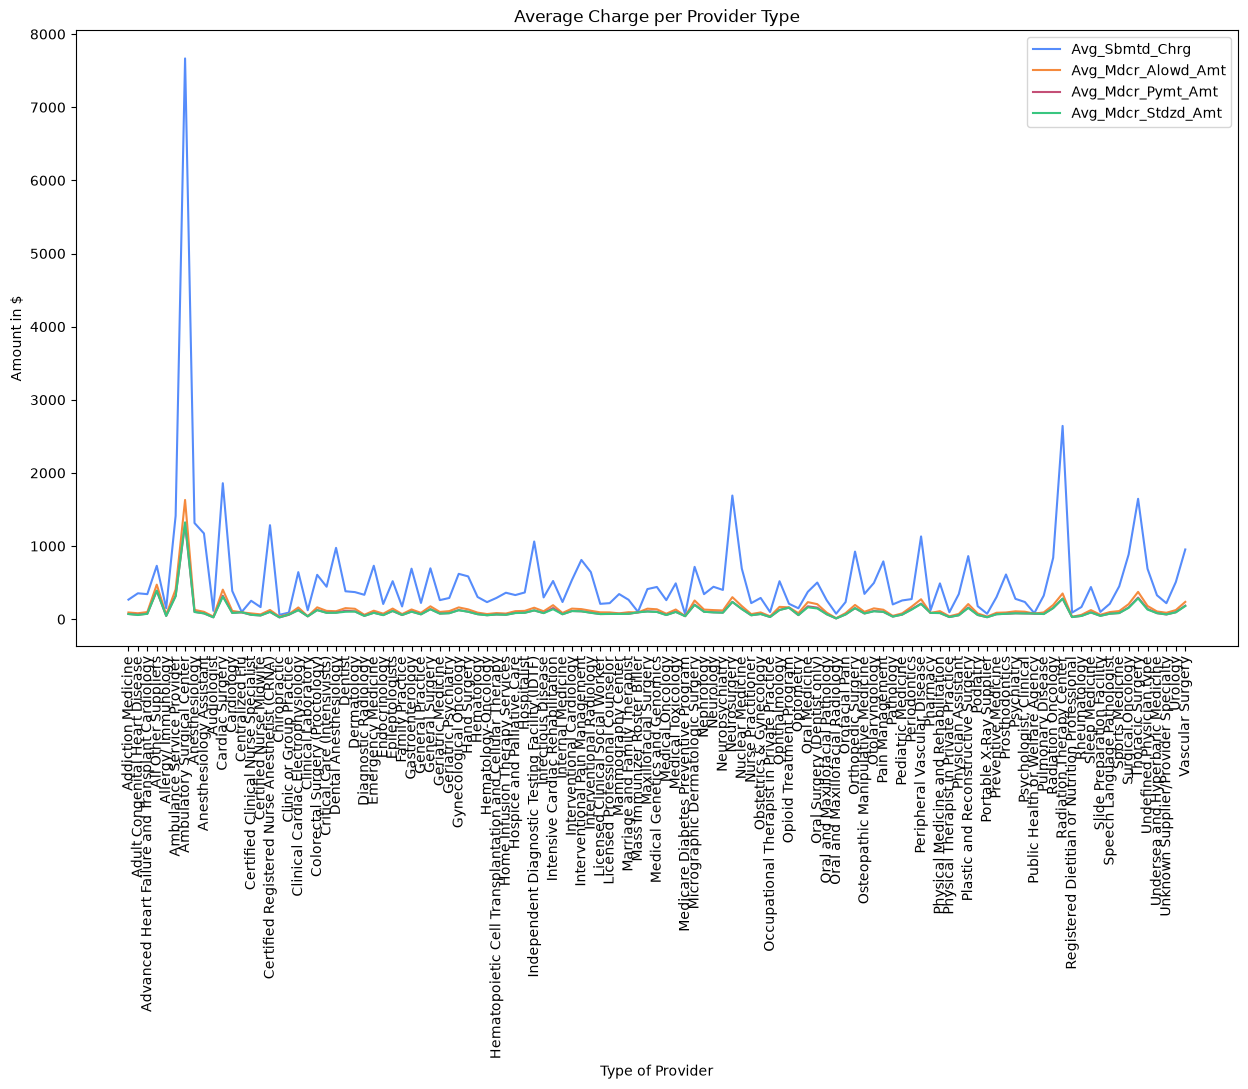

In [12]:
fig, ax = plt.subplots(figsize=(15,8))
main_type_avgCharge = main_data.groupby('Rndrng_Prvdr_Type')['Avg_Sbmtd_Chrg'].mean()
main_type_avgCharge.plot()
main_type_avgMdcrAmt = main_data.groupby('Rndrng_Prvdr_Type')['Avg_Mdcr_Alowd_Amt'].mean()
main_type_avgMdcrAmt.plot()
main_type_avgMdcrPymt = main_data.groupby('Rndrng_Prvdr_Type')['Avg_Mdcr_Pymt_Amt'].mean()
main_type_avgMdcrPymt.plot()
main_type_avgMdcrStdzd = main_data.groupby('Rndrng_Prvdr_Type')['Avg_Mdcr_Stdzd_Amt'].mean()
main_type_avgMdcrStdzd.plot()
ax.set_xticks(range(len(main_type_avgCharge.index)))
ax.set_xticklabels(main_type_avgCharge.index, rotation=90, fontsize=10)
plt.xlabel('Type of Provider')
plt.ylabel('Amount in $')
plt.title('Average Charge per Provider Type')
plt.legend()
plt.show()



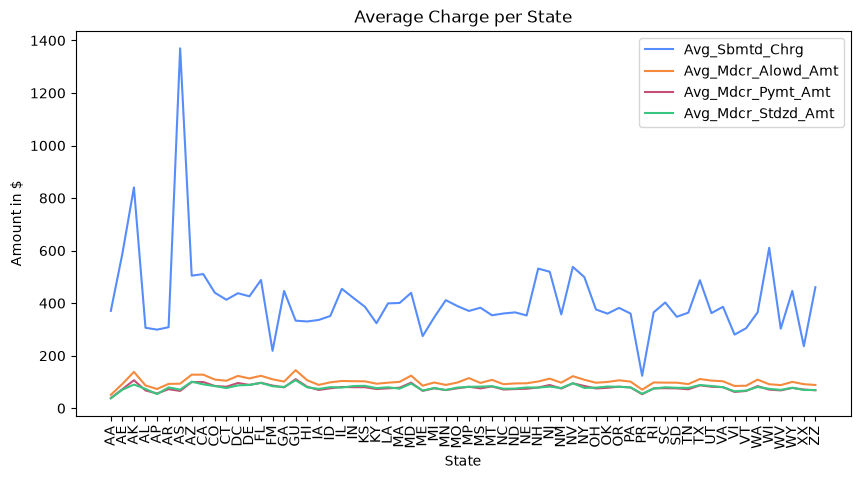

In [13]:
fig, ax = plt.subplots(figsize=(10,5))
main_state_avgCharge = main_data.groupby('Rndrng_Prvdr_State_Abrvtn')['Avg_Sbmtd_Chrg'].mean()
main_state_avgCharge.plot()
main_state_avgMdcrAmt = main_data.groupby('Rndrng_Prvdr_State_Abrvtn')['Avg_Mdcr_Alowd_Amt'].mean()
main_state_avgMdcrAmt.plot()
main_state_avgMdcrPymt = main_data.groupby('Rndrng_Prvdr_State_Abrvtn')['Avg_Mdcr_Pymt_Amt'].mean()
main_state_avgMdcrPymt.plot()
main_state_avgMdcrStdzd = main_data.groupby('Rndrng_Prvdr_State_Abrvtn')['Avg_Mdcr_Stdzd_Amt'].mean()
main_state_avgMdcrStdzd.plot()
ax.set_xticks(range(len(main_state_avgCharge.index)))
ax.set_xticklabels(main_state_avgCharge.index, rotation=90, )
plt.xlabel('State')
plt.ylabel('Amount in $')
plt.title('Average Charge per State')
plt.legend()
plt.show()

In [14]:
data_states = data['Rndrng_Prvdr_State_Abrvtn'].unique()
data_states

NameError: name 'data' is not defined

In [ ]:
for state in data_states:
    data_state_temp = data[data['Rndrng_Prvdr_State_Abrvtn']==state]
    data_state_temp.to_csv(f'data_{state}.csv')
    print(f'Exported data_{state}.csv')

In [ ]:
import pandas as pd

states = [
    "MD", "IL", "OH", "CO", "PA", "OK", "CA", "FL", "TX", "KY", "SC", "NV", "MO", "NY", "NJ", "VA", "LA", "TN", "MA", "OR","MI", "WA", "ME", "MN", "CT", "GA", "NC", "MS", "IA", "ND","ID", "NE", "AZ", "AL", "PR", "HI", "RI", "DC", "IN", "NM","AR", "WV", "VT", "NH", "AE", "KS", "DE", "WI", "MT", "WY","SD", "UT", "AK", "GU", "ZZ", "VI", "MP", "AP", "XX", "AA","FM", "AS"
]

data = {}

for state in states:
    data[state] = pd.read_csv(f"data/data_states/data_{state}.csv")


In [ ]:
data['MD']

In [ ]:
#fig, ax = plt.subplots()
data_MD_Last_Org_Name = data['MD'].groupby('Rndrng_Prvdr_Last_Org_Name')
#ax.plot(data['MD'], data['MD']['Avg_Sbmtd_Chrg'])
#plt.show()
data_MD_Last_Org_Name